# Why Did 2024 YR4's Impact Probability Rise Before It Fell?

*Matthew Payne*

In the two months after its discovery on 2024 December 27, the estimated chance that the asteroid 2024 YR4 would hit the Earth on 2032 December 22 climbed, and then collapsed. NASA's Center for Near-Earth Object Studies (CNEOS) reported more than 1% at the end of January, 2.3% on February 7, and 3.1% on February 18, "the highest impact probability NASA has ever recorded for an object of this size or larger"; then 1.5% a day later, and 0.004% on February 24 ([NASA Planetary Defense blog](https://science.nasa.gov/blogs/planetary-defense/)).

Rising and then falling is what impact probabilities usually do, for an object that will in fact miss, and it often surprises people: if more observations make the orbit better known, why does the danger first go *up*? This notebook answers that question, first with a toy model and then by reconstructing YR4's story from the observations themselves.

We will:

1. Build a toy model that shows why a shrinking uncertainty makes the impact probability rise and then fall, and predicts how high it can go.
2. Collect the observations of YR4 and work out *when each one reached the Minor Planet Center*, which is what matters for reconstructing what was known at each date.
3. Fit an orbit to the observations available at a series of dates, and map each orbit's uncertainty onto the *target plane* (b-plane) of the 2032 encounter.
4. Follow the impact probability through January and February 2025, and see the region of possible arrival points shrink past the Earth.
5. See how much the answer depends on how the observations are weighted.

This is the second notebook in a series on orbital uncertainty; the first ([NEOCP tracklets](../neocp_uncertainty/neocp_uncertainty.ipynb)) followed YR4's first three nights. Both use the `orbunc` toolkit in this repository, built on the [ASSIST](https://github.com/matthewholman/assist) integrator.

**Requirements:** as for the first notebook: `numpy`, `matplotlib`, `astropy`, `assist`, `rebound`, `requests` and `orbunc` (`pip install -e ./orbunc`), with the ASSIST ephemeris files (see the repository README).

**Run time:** about a minute from the cached results in `cache/`; about 45 minutes to recompute them (the Monte Carlo runs propagate 10,000 orbits to 2032 for each of 18 dates, three times over); a few minutes with `QUICK = True`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time
from erfa import ErfaWarning

warnings.simplefilter("ignore", ErfaWarning)   # UTC is undefined in 2032 (future leap seconds); harmless here

from orbunc import encounter, ephem, frames
import impact   # helper module in this folder: toy model, fits by date, figures

QUICK = False
CUTS = ["2024-12-29", "2025-01-01", "2025-01-08", "2025-01-15", "2025-01-22", "2025-01-29", "2025-02-03",
        "2025-02-07", "2025-02-12", "2025-02-15", "2025-02-18", "2025-02-19", "2025-02-20", "2025-02-21",
        "2025-02-22", "2025-02-24", "2025-03-05", "2025-04-15"]
N_MC, N_MC_ALT, CACHE = 10_000, 4_000, "cache"
if QUICK:
    CUTS, N_MC, N_MC_ALT, CACHE = CUTS[::3], 1_000, 1_000, "cache_quick"
KM = frames.AU_KM
rng = np.random.default_rng(2032)
ephem.get_ephem()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. A toy model

Picture the 2032 encounter on a target plane through the Earth's centre, perpendicular to the asteroid's approach (Section 3 makes this precise). A known orbit is a point on that plane; it hits if the point lies within the Earth's *capture radius* $b_\oplus$, a little larger than the Earth's radius because the Earth's gravity bends trajectories inwards. An uncertain orbit is a cloud of possible points, and the impact probability is the fraction of the cloud that falls on the Earth's disc.

For an asteroid observed for weeks, the cloud is extremely elongated: the orbit's shape is well determined, but small uncertainties in its period accumulate over eight years into a large uncertainty in *when* it arrives, which spreads it along one direction, $\zeta$. So consider a one-dimensional Gaussian along $\zeta$ with standard deviation $\sigma$, whose centre (the best-fitting orbit) lies a distance $\mu$ from the Earth. The impact probability is the area under the Gaussian over the Earth's width:

$$P(\sigma) = \Phi\!\left(\frac{b_\oplus - \mu}{\sigma}\right) - \Phi\!\left(\frac{-b_\oplus - \mu}{\sigma}\right) \approx \frac{2 b_\oplus}{\sigma\sqrt{2\pi}}\, e^{-\mu^2 / 2\sigma^2} \quad (\mu \gg b_\oplus).$$

As observations accumulate, $\sigma$ shrinks. While $\sigma \gg \mu$ the Earth sits near the middle of a cloud whose density grows as it shrinks, so $P \propto 1/\sigma$ *rises*. Once $\sigma$ becomes smaller than $\mu$ the cloud pulls away from the Earth and $P$ falls exponentially. The maximum is at $\sigma = \mu$:

$$P_{\max} \approx \sqrt{\frac{2}{\pi e}}\,\frac{b_\oplus}{\mu} \approx 0.48\,\frac{b_\oplus}{\mu}.$$

Remarkably, the peak depends only on how far the orbit really misses. For an object that hits ($\mu < b_\oplus$), $P$ instead rises all the way to 1.

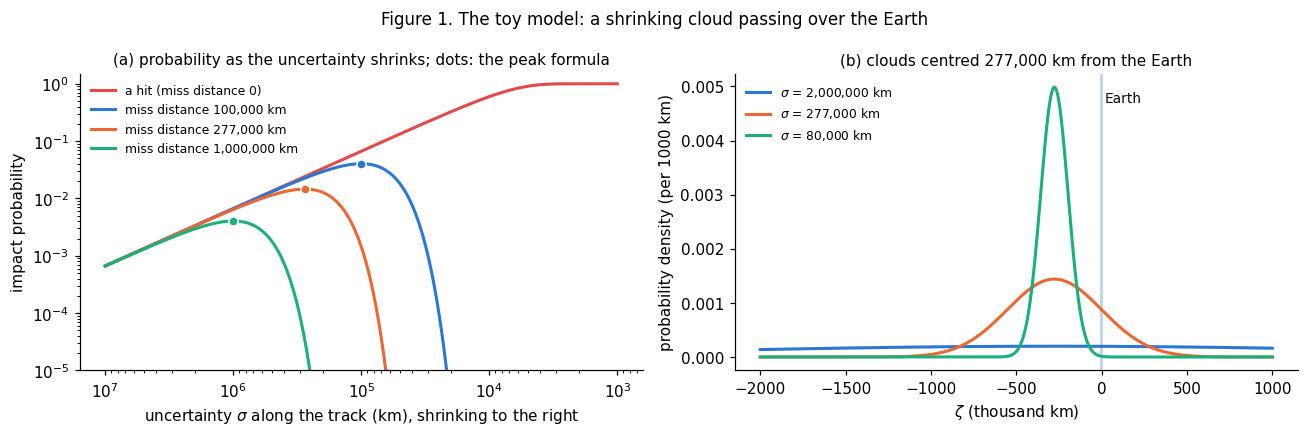

peak probability for a miss distance of 277,000 km: 1.46%


In [2]:
b_E = 8351.0          # km: YR4's capture radius (computed in Section 3)
sig = np.geomspace(1e3, 1e7, 400)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for mu, c in zip([0.0, 100_000, 277_000, 1_000_000], ["#e34948"] + impact.STAGE_COLOURS):
    from scipy.stats import norm
    P = norm.cdf((b_E - mu) / sig) - norm.cdf((-b_E - mu) / sig)
    axs[0].plot(sig, P, color=c, lw=2, label=f"miss distance {mu:,.0f} km" if mu else "a hit (miss distance 0)")
    if mu:
        axs[0].plot(mu, 0.484 * b_E / mu, "o", color=c, mec="white")
axs[0].set_xscale("log"); axs[0].set_yscale("log")
axs[0].set_ylim(1e-5, 1.5)
axs[0].invert_xaxis()
axs[0].set_xlabel(r"uncertainty $\sigma$ along the track (km), shrinking to the right")
axs[0].set_ylabel("impact probability")
axs[0].legend(fontsize=8, frameon=False)
axs[0].set_title("(a) probability as the uncertainty shrinks; dots: the peak formula", fontsize=10)

z = np.linspace(-2e6, 1e6, 2000)
for s_, c in zip([2e6, 277_000, 80_000], impact.STAGE_COLOURS):
    axs[1].plot(z / 1e3, norm.pdf(z, -277_000, s_) * 1e3, color=c, lw=2, label=rf"$\sigma$ = {s_:,.0f} km")
axs[1].axvspan(-b_E / 1e3, b_E / 1e3, color=impact.EARTH, alpha=0.3, lw=0)
axs[1].text(15, axs[1].get_ylim()[1] * 0.9, "Earth", color=impact.INK, fontsize=9)
axs[1].set_xlabel(r"$\zeta$ (thousand km)")
axs[1].set_ylabel("probability density (per 1000 km)")
axs[1].legend(fontsize=8, frameon=False)
axs[1].set_title("(b) clouds centred 277,000 km from the Earth", fontsize=10)
fig.suptitle("Figure 1. The toy model: a shrinking cloud passing over the Earth", fontsize=11)
plt.tight_layout()
plt.show()
print(f"peak probability for a miss distance of 277,000 km: {0.484 * b_E / 277_000:.2%}")

For YR4's true miss distance (Section 3), the toy model puts the peak at about 1.5%. Two things can change that in practice. The best-fitting orbit is not the true one: early on its centre wanders by about $\sigma$, and when it happens to sit closer to the Earth than the truth, the probability can rise higher than the toy model's peak (as it did in February 2025). And the cloud has a width across the track too; while that width is smaller than the Earth, as it is here, the one-dimensional picture holds.

## 2. Which observations were known, and when

To reconstruct what was known on a given date we need the observations that had *reached the Minor Planet Center* by then. That is not the same as the observations *made* by then: observers often send their measurements days or weeks later, and archival searches turn up "precovery" observations months later.

The MPC's observation identifier (`obsid`) encodes the moment at which the observation was submitted: its first eight characters are base-62 encodings of the submission date, the seconds of the day and the milliseconds (the MPC describes these identifiers as opaque, so this holds for current ones but is not guaranteed for the future). `orbunc.mpc.submission_times` decodes them.

492 ground-based observations; submission time decoded for 492
delay between observation and submission: median 8.8 h; 31% more than a day; 16% more than two weeks; longest 69 days


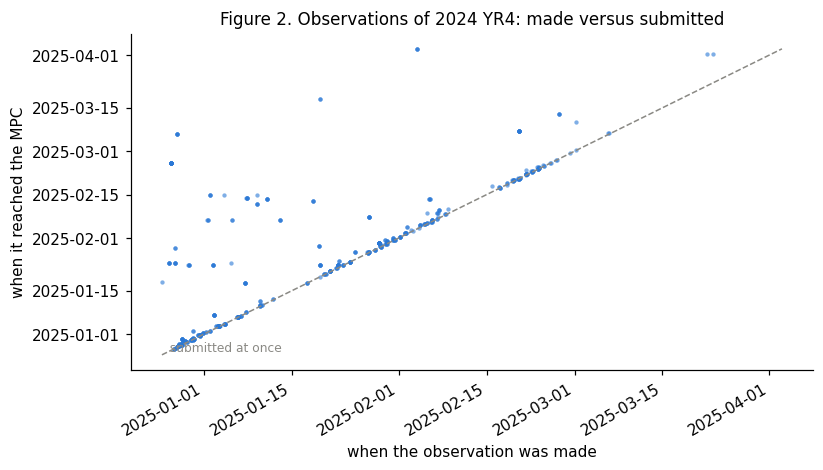


 date (0h UTC)  made before  submitted before
    2024-12-29           80                38
    2025-01-01          125                88
    2025-01-08          202               144
    2025-01-15          225               159
    2025-01-22          256               183
    2025-01-29          318               250
    2025-02-03          364               310
    2025-02-07          396               345
    2025-02-12          409               367
    2025-02-15          409               388
    2025-02-18          415               394
    2025-02-19          418               397
    2025-02-20          429               406
    2025-02-21          445               416
    2025-02-22          456               426
    2025-02-24          476               444
    2025-03-05          488               467
    2025-04-15          492               492


In [3]:
obs, submitted, truth = impact.load("2024 YR4")
t_orb, x_orb, _ = truth
lag = submitted - obs.jd_utc
print(f"{len(obs)} ground-based observations; submission time decoded for {np.isfinite(submitted).sum()}")
print(f"delay between observation and submission: median {np.median(lag) * 24:.1f} h; "
      f"{np.mean(lag > 1):.0%} more than a day; {np.mean(lag > 14):.0%} more than two weeks; longest {lag.max():.0f} days")

t_obs, t_sub = Time(obs.jd_utc, format="jd").datetime, Time(submitted, format="jd").datetime
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(t_obs, t_sub, s=8, color=impact.STAGE_COLOURS[0], alpha=0.6, lw=0)
lims = [min(t_obs), max(t_sub)]
ax.plot(lims, lims, color=impact.MUTED, lw=1, ls="--")
ax.text(lims[0], lims[0], "  submitted at once", fontsize=8, color=impact.MUTED, va="bottom")
ax.set_xlabel("when the observation was made")
ax.set_ylabel("when it reached the MPC")
fig.autofmt_xdate()
ax.set_title("Figure 2. Observations of 2024 YR4: made versus submitted", fontsize=11)
plt.show()

print(f"\n{'date (0h UTC)':>14s} {'made before':>12s} {'submitted before':>17s}")
for cut in CUTS:
    jd = Time(cut).jd
    print(f"{cut:>14s} {np.sum(obs.jd_utc < jd):12d} {np.sum(submitted < jd):17d}")

Most observations arrive within hours, but a substantial minority arrive weeks later, including pre-discovery observations made on 2024 December 25 and 26, some of which reached the MPC in late January and others in late February. Selecting by observation date would give each date information it did not yet have. (One caveat: if an observation was later re-measured, the MPC now serves only the new version, with its later submission time, so the original that orbit computers once had is missing from our reconstruction.)

## 3. Orbits by date, and the target plane

### 3.1 Fits

For each date we fit an orbit by least squares to the observations submitted before it, starting from the MPC's present orbit (the starting point does not matter; the fit converges to the best orbit for the data available). How the observations are weighted matters a great deal (Section 5); our baseline:

* each observation's reported uncertainty, or 1 arcsec if none was reported, but never less than 0.1 arcsec;
* when one station reports more than four positions in a night, their uncertainties are scaled by $\sqrt{N/4}$, as recommended by Vereš et al. (2017), because positions from the same night share systematic errors;
* outliers are rejected automatically: an observation whose $\chi^2$ exceeds 8 is dropped, and restored if it falls below 7 (Carpino, Milani & Chesley 2003).

### 3.2 The b-plane

The target plane, or *b-plane* (Öpik 1976; Valsecchi et al. 2003), passes through the Earth's centre perpendicular to the asteroid's incoming velocity relative to the Earth. Where the incoming asymptote of the asteroid's hyperbolic path around the Earth crosses this plane is its b-plane point. Its coordinate $\zeta$ measures whether the asteroid arrives early or late, and $\xi$ the closest the two orbits come; the asteroid hits if the point lies within the capture radius $b_\oplus = R_\oplus\sqrt{1 + v_{\rm esc}^2/v_\infty^2}$.

For each date we draw 10,000 orbits from the fit's uncertainty, propagate them all with ASSIST through the real Solar System (including the asteroid's 2028 close approach) to the 2032 encounter, and compute their b-plane points; orbits that strike the Earth are removed from the integration and counted as impacts. The fraction that hit is the Monte Carlo impact probability. We also compute the *linearised* prediction, which maps the fit's covariance to the b-plane through the derivatives of $(\xi, \zeta)$ with respect to the orbit, as a Gaussian.

First, the truth: the MPC's present orbit, fitted to two years of observations including those of the James Webb Space Telescope.

In [4]:
t_ca, d_ca = impact.closest_approach(x_orb, t_orb, "2032-12-22")
e_true = encounter.encounter(x_orb[None], t_orb, t_ca)
print(f"closest approach {Time(t_ca + ephem.JD_REF, format='jd', scale='tdb').utc.iso[:16]} UTC at {d_ca * KM:,.0f} km from the Earth's centre")
print(f"b-plane point: xi = {e_true.xi[0] * KM:,.0f} km, zeta = {e_true.zeta[0] * KM:,.0f} km; "
      f"capture radius {e_true.b_earth[0] * KM:,.0f} km; v_inf = {e_true.v_inf[0] * KM / 86400:.2f} km/s")
TRUTH = (e_true.xi[0] * KM, e_true.zeta[0] * KM)

closest approach 2032-12-22 08:22 UTC at 277,390 km from the Earth's centre
b-plane point: xi = -480 km, zeta = -276,854 km; capture radius 8,351 km; v_inf = 13.23 km/s


## 4. The rise and fall

Now the sequence: an orbit for each date, its b-plane cloud, and the impact probability. The results are cached in `cache/`; delete it to recompute (about 25 minutes).

In [5]:
tic = time.time()
seq = impact.bplane_sequence(obs, submitted, CUTS, truth, t_ca, N_MC, CACHE, rng, sigma_floor=0.1)
print(f"{len(seq)} dates in {time.time() - tic:.0f} s\n")
print(f"{'date':>11s} {'obs':>4s} {'rej':>4s} {'chi2/dof':>8s} {'zeta (km)':>22s} {'P (Monte Carlo)':>18s} {'P (linear)':>11s}")
for d in seq:
    m, C = d["lin_mean"] * KM, d["lin_cov"] * KM ** 2
    mc = f"{d['ip_mc']:.3%} ± {d['ip_mc_err']:.3%}" if d["impact"].sum() else f"< {d['ip_mc_err']:.2%}"
    print(f"{d['cut']:>11s} {int(d['nobs']):4d} {int(d['nrej']):4d} {float(d['chi2']) / int(d['dof']):8.2f} "
          f"{m[1]:>11,.0f} ± {np.sqrt(C[1, 1]):>8,.0f} {mc:>18s} {float(d['ip_lin']):11.4%}")

18 dates in 0 s

       date  obs  rej chi2/dof              zeta (km)    P (Monte Carlo)  P (linear)
 2024-12-29   38    1     0.27   2,451,255 ± 2,823,638    0.100% ± 0.032%     0.0919%
 2025-01-01   88    3     0.38   1,435,371 ± 1,393,059    0.400% ± 0.063%     0.2763%
 2025-01-08  144    3     0.36   2,278,091 ±  906,937    0.110% ± 0.033%     0.0305%
 2025-01-15  159    5     0.35   2,304,150 ±  889,821    0.090% ± 0.030%     0.0249%
 2025-01-22  183   11     0.36     227,396 ±  801,756    0.830% ± 0.091%     0.7459%
 2025-01-29  250   13     0.35    -222,533 ±  498,187    1.450% ± 0.120%     1.0865%
 2025-02-03  310   14     0.33    -385,445 ±  356,303    1.100% ± 0.104%     0.9408%
 2025-02-07  345   14     0.36    -119,184 ±  262,462    2.270% ± 0.149%     2.0928%
 2025-02-12  367   15     0.36    -266,311 ±  237,265    1.840% ± 0.134%     1.3532%
 2025-02-15  388   19     0.39    -329,464 ±  232,665    1.100% ± 0.104%     0.9494%
 2025-02-18  394   19     0.39    -260,662 ±  

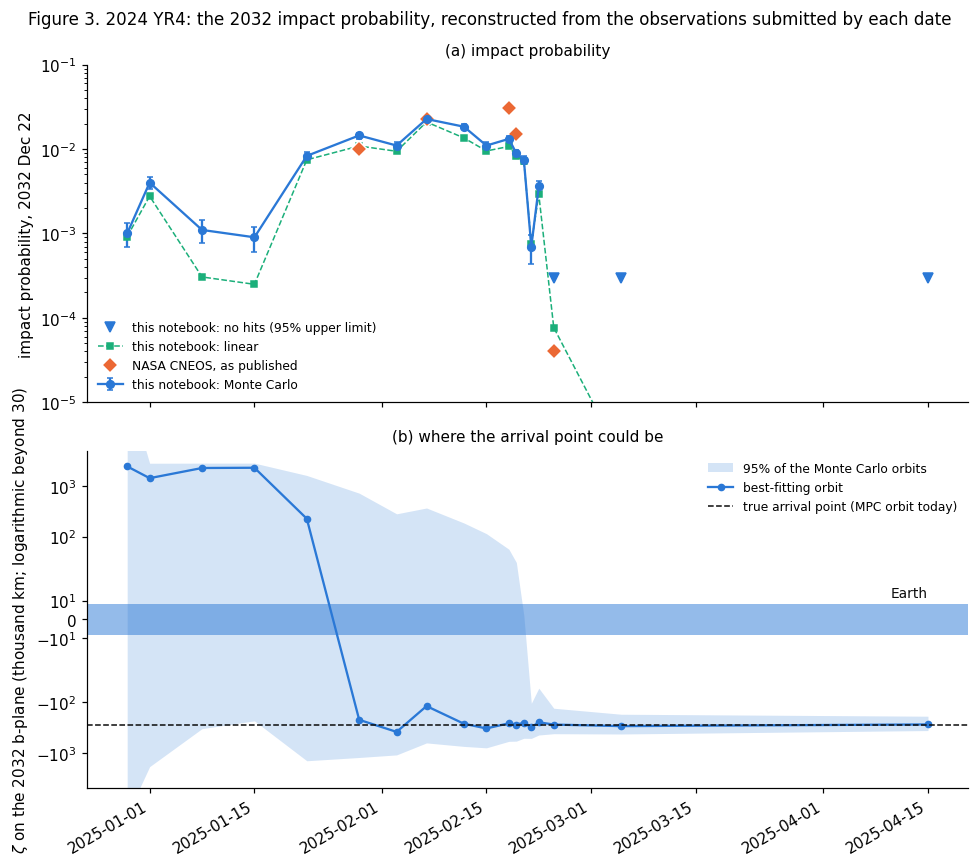

In [6]:
NASA = [("2025-01-29", 0.01, "more than 1%"), ("2025-02-07", 0.023, ""), ("2025-02-18", 0.031, ""),
        ("2025-02-19", 0.015, ""), ("2025-02-24", 0.00004, "")]
dates = Time(CUTS).datetime
fig, axs = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
ax = axs[0]
ip = np.array([d["ip_mc"] for d in seq]); err = np.array([d["ip_mc_err"] for d in seq])
hit = ip > 0
ax.errorbar(dates[hit], ip[hit], yerr=err[hit], fmt="o-", color=impact.STAGE_COLOURS[0], ms=5, lw=1.5, capsize=2, label="this notebook: Monte Carlo")
ax.plot(dates[~hit], err[~hit], "v", color=impact.STAGE_COLOURS[0], ms=6, label="this notebook: no hits (95% upper limit)")
ax.plot(dates, [max(float(d["ip_lin"]), 1e-7) for d in seq], "s--", color=impact.STAGE_COLOURS[2], ms=4, lw=1, label="this notebook: linear")
ax.plot(Time([n[0] for n in NASA]).datetime, [n[1] for n in NASA], "D", color=impact.STAGE_COLOURS[1], ms=7, mec="white", label="NASA CNEOS, as published")
ax.set_yscale("log")
ax.set_ylim(1e-5, 0.1)
ax.set_ylabel("impact probability, 2032 Dec 22")
ax.legend(fontsize=8, frameon=False, loc="lower left")
ax.set_title("(a) impact probability", fontsize=10)

ax = axs[1]
m = np.array([d["lin_mean"][1] for d in seq]) * KM / 1e3
s = np.array([np.sqrt(d["lin_cov"][1, 1]) for d in seq]) * KM / 1e3
lo, hi = (np.array([np.percentile(d["zeta"], q) for d in seq]) * KM / 1e3 for q in (2.5, 97.5))
ax.fill_between(dates, lo, hi, color=impact.STAGE_COLOURS[0], alpha=0.2, lw=0, label="95% of the Monte Carlo orbits")
ax.plot(dates, m, "o-", color=impact.STAGE_COLOURS[0], ms=4, lw=1.5, label="best-fitting orbit")
ax.axhspan(-e_true.b_earth[0] * KM / 1e3, e_true.b_earth[0] * KM / 1e3, color=impact.EARTH, alpha=0.5, lw=0)
ax.axhline(TRUTH[1] / 1e3, color=impact.INK, ls="--", lw=1, label="true arrival point (MPC orbit today)")
ax.text(dates[-1], 12, "Earth", ha="right", fontsize=9, color=impact.INK)
ax.set_yscale("symlog", linthresh=30)
ax.set_ylim(-5000, 5000)
ax.set_ylabel(r"$\zeta$ on the 2032 b-plane (thousand km; logarithmic beyond 30)")
ax.legend(fontsize=8, frameon=False, loc="upper right")
ax.set_title("(b) where the arrival point could be", fontsize=10)
fig.autofmt_xdate()
fig.suptitle("Figure 3. 2024 YR4: the 2032 impact probability, reconstructed from the observations submitted by each date", fontsize=11)
plt.tight_layout()
plt.show()

Panel (b) is the explanation of panel (a). In late December and early January the range of possible arrival points spans millions of kilometres and the Earth, about 17,000 km across including gravitational focusing, sits inside it: a small probability. Through January the range shrinks with the Earth still inside it, so the fraction of possible orbits that hit grows. By early February the spread (one standard deviation about 260,000 km on February 7) has become comparable to the distance of the cloud's centre from the Earth: the toy model's peak. As the range shrinks further through the second half of February, the Earth falls outside it and the probability collapses. The final range is centred on the true arrival point, about 277,000 km from the Earth's centre.

The reconstruction follows the published values in shape and timing: a rise through January to about 2% in early February, matching CNEOS's 2.3% on February 7, then a collapse in the last week of February, to below 0.01% by February 24, as published. In between, CNEOS's estimate rose to 3.1% on February 18 while ours was already falling. We do not expect agreement in detail: CNEOS used its own weighting of the observations, and the data it had on a given day may differ from ours (Section 2's caveat). Section 5 shows how much the weighting alone changes the answer. Note also that the peak, about 2.3%, is above the toy model's 1.5%: on February 7 the best-fitting orbit happened to arrive closer to the Earth than the true one, just as Section 1 anticipated.

Figure 4 shows the clouds themselves on the b-plane at four dates. Note the very different scales of the two axes: the clouds are only thousands of kilometres wide, but millions long.

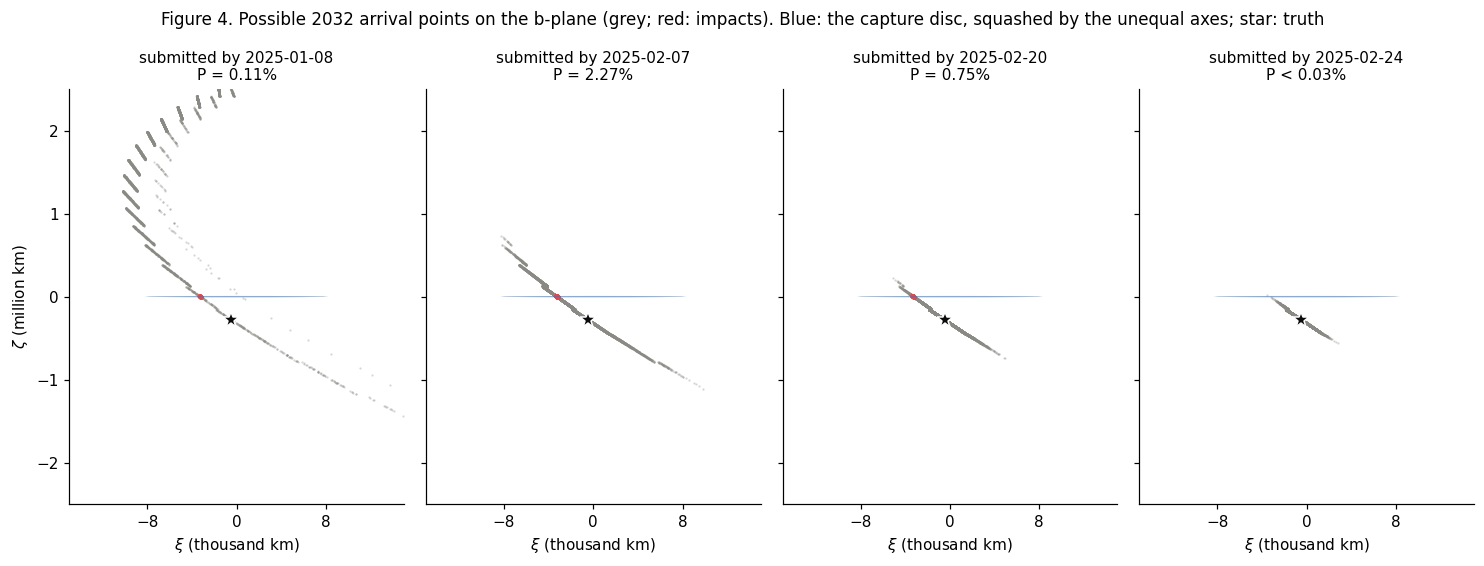

In [7]:
show = [c for c in ["2025-01-08", "2025-02-07", "2025-02-20", "2025-02-24"] if c in CUTS]
fig, axs = plt.subplots(1, len(show), figsize=(3.4 * len(show), 5.2), sharey=True)
for ax, cut in zip(np.atleast_1d(axs), show):
    d = seq[CUTS.index(cut)]
    p = f"P = {d['ip_mc']:.2%}" if d["impact"].sum() else f"P < {d['ip_mc_err']:.2%}"
    impact.plot_bplane(ax, d, xi_lim_km=15_000, zeta_lim_km=2_500_000, title=f"submitted by {cut}\n{p}", truth=TRUTH)
    if ax is not np.atleast_1d(axs)[0]:
        ax.set_ylabel("")
fig.suptitle("Figure 4. Possible 2032 arrival points on the b-plane (grey; red: impacts). Blue: the capture disc, squashed by the unequal axes; star: truth", fontsize=11)
plt.tight_layout()
plt.show()

## 5. How much does the weighting matter?

Everything above depends on how much weight each observation gets. Our baseline floor of 0.1 arcsec is a judgement: lower, and the fit trusts the best observations more (and rejects more observations as outliers); higher, and it trusts them less. Here is the whole sequence again with floors of 0.05 and 0.2 arcsec (with fewer Monte Carlo orbits, to save time).

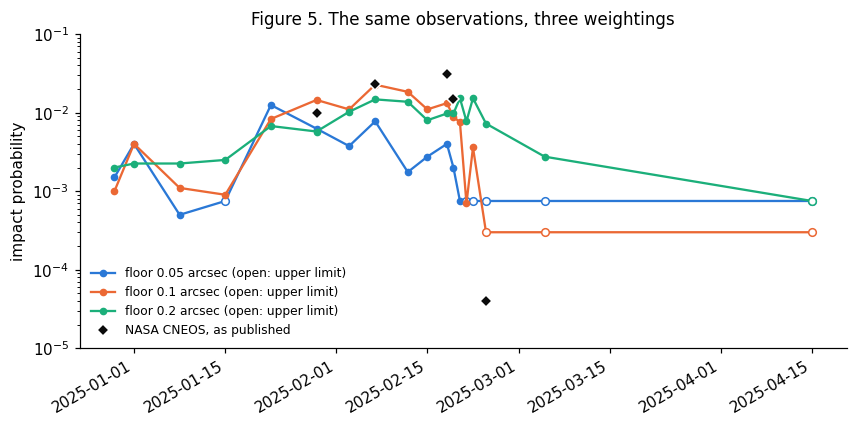

floor 0.05: final fit chi2/dof = 0.53, 30 observations rejected
floor 0.1: final fit chi2/dof = 0.39, 19 observations rejected
floor 0.2: final fit chi2/dof = 0.26, 6 observations rejected


In [8]:
alt = {f: impact.bplane_sequence(obs, submitted, CUTS, truth, t_ca, N_MC_ALT, CACHE, rng, sigma_floor=f) for f in (0.05, 0.2)}
alt[0.1] = seq
fig, ax = plt.subplots(figsize=(9, 4.2))
for f, c in zip((0.05, 0.1, 0.2), impact.STAGE_COLOURS):
    ip = np.array([d["ip_mc"] for d in alt[f]]); err = np.array([d["ip_mc_err"] for d in alt[f]])
    ax.plot(dates, np.where(ip > 0, ip, err), "o-", color=c, ms=4, lw=1.5, label=f"floor {f} arcsec (open: upper limit)")
    ax.plot(dates[ip == 0], err[ip == 0], "o", color="white", mec=c, ms=5)
ax.plot(Time([n[0] for n in NASA]).datetime, [n[1] for n in NASA], "D", color=impact.INK, ms=6, mec="white", label="NASA CNEOS, as published")
ax.set_yscale("log")
ax.set_ylim(1e-5, 0.1)
ax.set_ylabel("impact probability")
ax.legend(fontsize=8, frameon=False, loc="lower left")
fig.autofmt_xdate()
ax.set_title("Figure 5. The same observations, three weightings", fontsize=11)
plt.show()
for f in (0.05, 0.1, 0.2):
    d = alt[f][-1]
    print(f"floor {f}: final fit chi2/dof = {float(d['chi2']) / int(d['dof']):.2f}, {int(d['nrej'])} observations rejected")

The weighting changes the height of the peak by a factor of about two, and the date on which an impact is effectively ruled out by weeks. None of these weightings is "right": the reduced $\chi^2$ of every fit is below 1, which says that on average the uncertainties we assign are too large, partly because many observations come with no uncertainty at all and get the default of 1 arcsec; yet lowering the floor makes the fit reject more observations as outliers, which says some reported uncertainties are too small. Orbit computers address this with weighting schemes calibrated on the statistics of millions of residuals (Vereš et al. 2017), and different centres make different choices: one reason why the impact probabilities published by different centres for the same object can differ.

What does not depend on the weighting is the shape of the story: a rise while the uncertainty region shrinks with the Earth inside it, then a collapse once it shrinks past the Earth.

## 6. Summary

* An impact probability is the fraction of the uncertainty region on the target plane that covers the Earth. For an object that will miss, it rises while the region shrinks around the Earth and falls once the region shrinks past it; the peak is about $0.48\, b_\oplus/\mu$ for a true miss distance $\mu$, about 1.5% for YR4.
* To reconstruct what was known on a date, select observations by when they *reached the MPC*. For YR4 a substantial minority arrived weeks after they were made.
* Reconstructed from the observations alone, YR4's 2032 impact probability rose through January 2025 to about 2% in early February and collapsed in the last week of February, as published; the published estimate peaked later and higher (3.1% on February 18).
* How observations are weighted changes the numbers substantially, but not the shape of the story.
* The linearised (Gaussian) b-plane probability is several times too low in early January, when the cloud on the b-plane is visibly curved (Figure 4); from late January, when the uncertainty region is small enough for the linear approximation, the two agree to within about 30%.

## 7. Going further

* **Other dates and objects.** Change `CUTS`, or load another object with `impact.load(designation)` and choose its encounter date.
* **The Moon.** As the Earth was ruled out, the chance that YR4 would hit the Moon in 2032 became the question; NASA reported 3.8% in April 2025 and 4.3% in June, before James Webb Space Telescope observations in early 2026 ruled it out ([NASA, 2026 March 5](https://science.nasa.gov/blogs/planetary-defense/2026/03/05/new-nasa-asteroid-observations-eliminate-chance-of-2032-lunar-impact/)). The same machinery, with the Moon as the target, could follow that story.
* **Next in this series:** an asteroid that did hit, and how its predicted impact corridor on the Earth's surface narrowed as observations came in.

## References

* Carpino, M., Milani, A. & Chesley, S. R. (2003), *Error statistics of asteroid optical astrometric observations*, Icarus 166, 248. [ADS](https://ui.adsabs.harvard.edu/abs/2003Icar..166..248C/abstract)
* Holman, M. J., Akmal, A., Farnocchia, D., et al. (2023), *ASSIST: An Ephemeris-quality Test-particle Integrator*, PSJ 4, 69. [ADS](https://ui.adsabs.harvard.edu/abs/2023PSJ.....4...69H/abstract)
* Milani, A., Chesley, S. R., Chodas, P. W. & Valsecchi, G. B. (2002), *Asteroid close approaches: analysis and potential impact detection*, in Asteroids III, 55. [ADS](https://ui.adsabs.harvard.edu/abs/2002aste.book...55M/abstract)
* NASA Planetary Defense blog posts on 2024 YR4: [2025 Jan 29](https://science.nasa.gov/blogs/planetary-defense/2025/01/29/nasa-shares-observations-of-recently-identified-near-earth-asteroid/), [Feb 7](https://science.nasa.gov/blogs/planetary-defense/2025/02/07/nasa-continues-to-monitor-orbit-of-near-earth-asteroid-2024-yr4/), [Feb 19](https://science.nasa.gov/blogs/planetary-defense/2025/02/19/dark-skies-bring-new-observations-of-asteroid-2024-yr4-lower-impact-probability/), [Feb 24](https://science.nasa.gov/blogs/planetary-defense/2025/02/24/latest-calculations-conclude-asteroid-2024-yr4-now-poses-no-significant-threat-to-earth-in-2032-and-beyond/).
* Öpik, E. J. (1976), *Interplanetary Encounters: Close-Range Gravitational Interactions*, Elsevier. [ADS](https://ui.adsabs.harvard.edu/abs/1976iecg.book.....O/abstract)
* Pham, D., Rein, H. & Spiegel, D. S. (2024), *A new timestep criterion for N-body simulations*, OJAp 7, 1. [ADS](https://ui.adsabs.harvard.edu/abs/2024OJAp....7E...1P/abstract)
* Valsecchi, G. B., Milani, A., Gronchi, G. F. & Chesley, S. R. (2003), *Resonant returns to close approaches: Analytical theory*, A&A 408, 1179. [ADS](https://ui.adsabs.harvard.edu/abs/2003A%26A...408.1179V/abstract)
* Vereš, P., Farnocchia, D., Chesley, S. R. & Chamberlin, A. B. (2017), *Statistical analysis of astrometric errors for the most productive asteroid surveys*, Icarus 296, 139. [ADS](https://ui.adsabs.harvard.edu/abs/2017Icar..296..139V/abstract)